# **Revised Project Ideation: Does Marriage Buy Happiness? (1972-2024)**

Objective: re-ask the Assignment 01 question with **marital status** in place of family income —
whether married adults report systematically higher happiness than widowed, divorced, separated and
never-married adults, and whether that national picture has changed between 1972 and 2024.

| Housekeeping | |
|---|---|
| Course code | CISC7204 |
| Course title | Data Science and Data Visualization |
| Coursework item | Assignment 02 - Revised Project Ideation (Pair Work) |
| Authors | UN CHI KIT (mc65308), Kelden Jamtsho (mc66418) |

# Setup

Same stack as Assignment 01: `pandas` for the survey data, `numpy` for the numerics, `scipy.stats` for the
tests, `statsmodels` for the regressions and `matplotlib` for the figures.

In [1]:
# standard library
import io
import json
import zipfile
from pathlib import Path
from urllib.request import Request, urlopen

# scientific stack
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 110

<a id="Data-Acquisition"></a>
# Task 1 : Data Acquisition

Two sources, same as Assignment 01: the **General Social Survey** for the individual-level happiness and
marital-status answers, and **World Bank** GDP per capita as the national economic context. Both are cached
on disk, so a re-run reads the cache instead of the network.

In [2]:
# --- 1.1  GSS: download the per-year Stata files (data source #1) ---
DATA_DIR = Path('data')
GSS_DIR  = DATA_DIR / 'gss_year'
GSS_DIR.mkdir(parents=True, exist_ok=True)

# every GSS wave that publishes HAPPY and REALINC, 1972-2024 (35 waves)
SURVEY_YEARS = [1972, 1973, 1974, 1975, 1976, 1977, 1978, 1980,
                1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991,
                1993, 1994, 1996, 1998, 2000, 2002, 2004, 2006, 2008, 2010,
                2012, 2014, 2016, 2018, 2021, 2022, 2024]
GSS_ZIP_URL  = ('https://gss.norc.org/content/dam/gss/get-the-data/documents/stata/'
                '{year}_stata.zip')

def fetch_gss_year(year):
    """Download <year>_stata.zip and return the path of the extracted .dta file."""
    target = GSS_DIR / f'GSS{year}.dta'
    if target.exists():                       # already downloaded by an earlier run
        return target
    request = Request(GSS_ZIP_URL.format(year=year),
                      headers={'User-Agent': 'Mozilla/5.0'})
    with urlopen(request, timeout=180) as response:
        blob = response.read()
    with zipfile.ZipFile(io.BytesIO(blob)) as archive:
        member = next(n for n in archive.namelist() if n.lower().endswith('.dta'))
        target.write_bytes(archive.read(member))
    return target

gss_files = {year: fetch_gss_year(year) for year in SURVEY_YEARS}

print(f'{"year":>6}  {"file size":>10}  path')
for year, path in gss_files.items():
    print(f'{year:>6}  {path.stat().st_size / 1e6:>8.2f} MB  {path}')

  year   file size  path
  1972      1.04 MB  data\gss_year\GSS1972.dta
  1973      1.28 MB  data\gss_year\GSS1973.dta
  1974      1.32 MB  data\gss_year\GSS1974.dta
  1975      1.52 MB  data\gss_year\GSS1975.dta
  1976      1.57 MB  data\gss_year\GSS1976.dta
  1977      1.67 MB  data\gss_year\GSS1977.dta
  1978      1.70 MB  data\gss_year\GSS1978.dta
  1980      1.71 MB  data\gss_year\GSS1980.dta
  1982      2.15 MB  data\gss_year\GSS1982.dta
  1983      1.88 MB  data\gss_year\GSS1983.dta
  1984      2.05 MB  data\gss_year\GSS1984.dta
  1985      2.16 MB  data\gss_year\GSS1985.dta
  1986      1.86 MB  data\gss_year\GSS1986.dta
  1987      2.58 MB  data\gss_year\GSS1987.dta
  1988      2.32 MB  data\gss_year\GSS1988.dta
  1989      2.38 MB  data\gss_year\GSS1989.dta
  1990      2.39 MB  data\gss_year\GSS1990.dta
  1991      2.44 MB  data\gss_year\GSS1991.dta
  1993      2.23 MB  data\gss_year\GSS1993.dta
  1994      4.71 MB  data\gss_year\GSS1994.dta
  1996      5.23 MB  data\gss_year\

In [3]:
# --- 1.2  World Bank: real GDP per capita, USA (data source #2) ---
WB_URL   = ('https://api.worldbank.org/v2/country/USA/indicator/NY.GDP.PCAP.KD'
            '?format=json&per_page=1000&date=1972:2024')
WB_CACHE = DATA_DIR / 'worldbank_gdp_pc_usa.json'

def fetch_wb_gdp():
    """Return {year: real GDP per capita in constant 2015 US$}."""
    if WB_CACHE.exists():
        payload = json.loads(WB_CACHE.read_text())
    else:
        request = Request(WB_URL, headers={'User-Agent': 'Mozilla/5.0'})
        with urlopen(request, timeout=60) as response:
            payload = json.loads(response.read().decode())
        WB_CACHE.write_text(json.dumps(payload))
    return {int(row['date']): row['value']
            for row in payload[1] if row['value'] is not None}

gdp_pc = fetch_wb_gdp()

gdp_table = (pd.Series(gdp_pc, name='gdp_per_capita')
               .rename_axis('year').reset_index()
               .query('year in @SURVEY_YEARS'))
print('World Bank: GDP per capita, USA (constant 2015 US$)')
print(gdp_table.to_string(index=False))
print()
print(f'GDP per capita {SURVEY_YEARS[0]}: ${gdp_pc[SURVEY_YEARS[0]]:>9,.0f}')
print(f'GDP per capita {SURVEY_YEARS[-1]}: ${gdp_pc[SURVEY_YEARS[-1]]:>9,.0f}')
print(f'ratio {SURVEY_YEARS[-1]}/{SURVEY_YEARS[0]} = '
      f'{gdp_pc[SURVEY_YEARS[-1]] / gdp_pc[SURVEY_YEARS[0]]:.2f}x')

World Bank: GDP per capita, USA (constant 2015 US$)
 year  gdp_per_capita
 2024    66856.513170
 2022    64322.233282
 2021    63096.785615
 2018    59817.655680
 2016    57430.849930
 2014    55665.241119
 2012    54000.841078
 2010    52812.682987
 2008    53703.962898
 2006    53596.315236
 2004    51348.347339
 2002    48967.366122
 2000    48616.254628
 1998    45596.430688
 1996    42783.816572
 1994    41106.988183
 1993    40002.476225
 1991    38637.839818
 1990    39200.065809
 1989    38911.541896
 1988    37889.377346
 1987    36701.945387
 1986    35794.887775
 1985    34918.130204
 1984    33818.823552
 1983    31810.921608
 1982    30696.083438
 1980    31081.621632
 1978    30834.999232
 1977    29528.966368
 1976    28509.143059
 1975    27309.868818
 1974    27637.299776
 1973    28042.551918
 1972    26798.533611

GDP per capita 1972: $   26,799
GDP per capita 2024: $   66,857
ratio 2024/1972 = 2.49x


<a id="Data-Wrangling"></a>
# Task 2 : Data Wrangling

Three differences from Assignment 01, all deliberate:

1. **`MARITAL` replaces `REALINC` as the explanatory variable.** Codes `1 = married`, `2 = widowed`,
   `3 = divorced`, `4 = separated`, `5 = never married`. Unlike income, this variable is *nominal*, so it is
   modelled with dummies rather than ranked.
2. **The main sample is not filtered on income.** Assignment 01 dropped respondents without a usable
   `REALINC`. Doing that here would distort the marital composition the project is trying to describe, so the
   main sample keeps every respondent with a valid happiness answer and one of the five marital codes.
   Family income enters only as a control in the adjusted regression.
3. **The national series is computed from the GSS itself** — the share of respondents married per wave — so
   the individual and national analyses share one definition of "married". A cross-source comparison with
   NCHS vital-statistics marriage rates would mix two different denominators.

In [4]:
# --- 2.1  Load the variables the proposal needs, for every survey year ---
VARS = ['year', 'happy', 'marital', 'age', 'sex', 'realinc']

raw = pd.concat(
    [pd.read_stata(gss_files[year], convert_categoricals=False, columns=VARS)
     for year in SURVEY_YEARS],
    ignore_index=True)

print(f'{len(raw):,} raw rows across {raw.year.nunique()} survey waves')
print()
print(raw.groupby('year').size().rename('respondents').to_string())

76,981 raw rows across 35 survey waves

year
1972    1613
1973    1504
1974    1484
1975    1490
1976    1499
1977    1530
1978    1532
1980    1468
1982    1860
1983    1599
1984    1473
1985    1534
1986    1470
1987    1819
1988    1481
1989    1537
1990    1372
1991    1517
1993    1606
1994    2992
1996    2904
1998    2832
2000    2817
2002    2765
2004    2812
2006    4510
2008    2023
2010    2044
2012    1974
2014    2538
2016    2867
2018    2348
2021    4032
2022    4149
2024    3986


In [5]:
# --- 2.2  Clean: valid happiness codes, one of the five marital codes ---
df = raw[raw.happy.isin([1, 2, 3])].copy()

# MARITAL is stored with labels in some releases; coerce, then keep the five real statuses
df['marital'] = pd.to_numeric(df.marital, errors='coerce').astype('Int64')
df = df[df.marital.isin([1, 2, 3, 4, 5])].copy()
df['marital'] = df.marital.astype(int)

# recode: 3 = very happy, 2 = pretty happy, 1 = not too happy
df['H'] = 4 - df.happy

STATUS = {1: 'married', 2: 'widowed', 3: 'divorced', 4: 'separated', 5: 'never married'}
df['status'] = df.marital.map(STATUS)

print(f'usable respondents: {len(df):,} of {len(raw):,} raw rows '
      f'({len(df) / len(raw) * 100:.1f}% retained)')
print(f'survey waves: {df.year.nunique()} ({df.year.min()}-{df.year.max()})')
print()
print('happiness distribution:')
print(df.happy.value_counts().sort_index()
        .rename(index={1: 'very happy', 2: 'pretty happy', 3: 'not too happy'})
        .rename('respondents').to_string())

usable respondents: 72,087 of 76,981 raw rows (93.6% retained)
survey waves: 35 (1972-2024)

happiness distribution:
happy
very happy       21269
pretty happy     40409
not too happy    10409


In [6]:
# --- 2.3  Every status has to appear in every wave, or the annual series is not comparable ---
by_year = pd.crosstab(df.year, df.status)
print('respondents by survey wave and marital status:')
print(by_year.to_string())
print()
print('smallest (wave, status) cell:', int(by_year.to_numpy().min()))
print('all five statuses present in every wave:',
      bool((by_year.to_numpy() > 0).all()))

respondents by survey wave and marital status:
status  divorced  married  never married  separated  widowed
year                                                        
1972          65     1157            209         39      136
1973          60     1074            193         51      122
1974          76     1064            183         37      120
1975          84      998            210         49      144
1976          98      974            207         51      169
1977         102      974            225         61      165
1978         132      954            232         46      152
1980         125      886            240         47      164
1982         203      992            349         90      221
1983         155      958            253         48      159
1984         160      814            278         42      151
1985         168      870            267         65      160
1986         143      820            258         60      168
1987         217      900            3

<a id="EDA"></a>
# Task 3 : Exploratory Data Analysis

The first table is the raw evidence — respondents per (marital status, happiness) cell — and the second
converts it into the percentage "very happy" per status, with a 95% confidence interval on the mean.

In [7]:
order = [STATUS[i] for i in range(1, 6)]

counts = (pd.crosstab(df.status, df.happy)
            .rename(columns={1: 'very happy', 2: 'pretty happy', 3: 'not too happy'})
            .reindex(order))
print('respondents by marital status and happiness (GSS 1972-2024 pooled):')
print(counts.to_string())
print()

summary = (df.groupby('status')
             .agg(n=('H', 'size'),
                  mean_happiness=('H', 'mean'),
                  sd=('H', 'std'),
                  pct_very_happy=('happy', lambda s: (s == 1).mean() * 100))
             .reindex(order))
summary['ci95'] = 1.96 * summary.sd / np.sqrt(summary.n)

print('happiness by marital status, 95% CI on the mean:')
print(summary.round(3).to_string())

respondents by marital status and happiness (GSS 1972-2024 pooled):
happy          very happy  pretty happy  not too happy
status                                                
married             14409         19598           3130
widowed              1512          3757           1382
divorced             1768          5740           2015
separated             375          1335            706
never married        3205          9979           3176

happiness by marital status, 95% CI on the mean:
                   n  mean_happiness     sd  pct_very_happy   ci95
status                                                            
married        37137           2.304  0.616          38.800  0.006
widowed         6651           2.020  0.659          22.733  0.016
divorced        9523           1.974  0.630          18.566  0.013
separated       2416           1.863  0.655          15.522  0.026
never married  16360           2.002  0.625          19.590  0.010


In [8]:
# --- is the pattern significant, or could it be sampling noise? ---
chi2, p_chi2, dof, expected = stats.chi2_contingency(pd.crosstab(df.marital, df.happy))
cramers_v = np.sqrt(chi2 / (len(df) * (min(expected.shape) - 1)))

p_chi2_txt = f'{p_chi2:.3e}' if p_chi2 > 0 else 'below 1e-300 (underflows)'
print('is marital status associated with happiness at all?')
print(f'  chi2({dof}) = {chi2:.1f},  p {p_chi2_txt},  n = {len(df):,}')
print(f"  Cramer's V = {cramers_v:.3f}   (0.1 small, 0.3 medium, 0.5 large)")

is marital status associated with happiness at all?
  chi2(8) = 4513.7,  p below 1e-300 (underflows),  n = 72,087
  Cramer's V = 0.177   (0.1 small, 0.3 medium, 0.5 large)


<a id="Model-Development"></a>
# Task 4 : Model Development

**Why dummies and not a score.** Income quintiles in Assignment 01 were ordered, so a single slope was
meaningful. Marital status is *nominal* — widowed, divorced, separated and never married are four different
social situations, not four steps up a ladder — so ranking them into an ordinal score or a Spearman-style
"quintile" analysis would impose an order the data do not have. The model below therefore uses four
indicator variables with **married** as the reference category, so each coefficient is "this group's
happiness, minus married respondents' happiness, on the 1-3 scale".

In [9]:
D = pd.DataFrame({f'm{i}': (df.marital == i).astype(float) for i in [2, 3, 4, 5]})
ols = sm.OLS(df.H.astype(float), sm.add_constant(D)).fit()

print('OLS: happiness (1-3) on marital status, reference = married')
print(f'  {"status":<16}{"coef":>8}{"p":>12}')
print(f'  {"married (ref)":<16}{0.0:>8.3f}{"-":>12}')
for i in [2, 3, 4, 5]:
    print(f'  {STATUS[i]:<16}{ols.params[f"m{i}"]:>8.3f}{ols.pvalues[f"m{i}"]:>12.1e}')
print()
print(f'  R2 = {ols.rsquared:.3f},  n = {int(ols.nobs):,}')

OLS: happiness (1-3) on marital status, reference = married
  status              coef           p
  married (ref)      0.000           -
  widowed           -0.284    3.6e-253
  divorced          -0.330     0.0e+00
  separated         -0.441    5.0e-245
  never married     -0.302     0.0e+00

  R2 = 0.061,  n = 72,087


In [10]:
# --- does the gap survive age, sex and family-income controls? ---
adj = df[df.age.notna() & df.sex.notna() & df.realinc.notna()].copy()
adj = adj[(adj.realinc > 0) & (adj.realinc < 1e6)].copy()

X_adj = pd.concat(
    [pd.DataFrame({f'm{i}': (adj.marital == i).astype(float) for i in [2, 3, 4, 5]}, index=adj.index),
     adj[['age', 'sex', 'realinc']].astype(float)],
    axis=1)
ols_adj = sm.OLS(adj.H.astype(float), sm.add_constant(X_adj)).fit()

print(f'adjusted model: {len(adj):,} respondents with age, sex and family income')
print(f'  {"status":<16}{"unadjusted":>12}{"adjusted":>10}{"p (adjusted)":>14}')
for i in [2, 3, 4, 5]:
    print(f'  {STATUS[i]:<16}{ols.params[f"m{i}"]:>12.3f}'
          f'{ols_adj.params[f"m{i}"]:>10.3f}{ols_adj.pvalues[f"m{i}"]:>14.1e}')
print()
print(f'  R2: {ols.rsquared:.3f} -> {ols_adj.rsquared:.3f}')

adjusted model: 64,321 respondents with age, sex and family income
  status            unadjusted  adjusted  p (adjusted)
  widowed               -0.284    -0.248      6.7e-133
  divorced              -0.330    -0.292       0.0e+00
  separated             -0.441    -0.401      7.6e-182
  never married         -0.302    -0.252      8.4e-305

  R2: 0.061 -> 0.070


In [11]:
# --- effect sizes: Cohen's d, odds ratio with a Woolf interval, bootstrap gap ---
m_arr  = (df[df.marital == 1].happy == 1).to_numpy(dtype=float)
nv_arr = (df[df.marital == 5].happy == 1).to_numpy(dtype=float)
m_all, nv_all = df[df.marital == 1].H, df[df.marital == 5].H
nm, nnv = len(m_all), len(nv_all)

pooled_sd = np.sqrt(((nm - 1) * m_all.std()**2 + (nnv - 1) * nv_all.std()**2) / (nm + nnv - 2))
d_cohen = (m_all.mean() - nv_all.mean()) / pooled_sd
print(f"Cohen's d (mean happiness, married vs never married) = {d_cohen:.3f}")

a = int(((df.marital == 1) & (df.happy == 1)).sum())      # very happy, married
b = int((df.marital == 1).sum()) - a                       # not very happy, married
c = int(((df.marital == 5) & (df.happy == 1)).sum())       # very happy, never married
e = int((df.marital == 5).sum()) - c                       # not very happy, never married
odds_ratio = (a * e) / (b * c)
se_logor = np.sqrt(1 / a + 1 / b + 1 / c + 1 / e)
ci_or = (np.exp(np.log(odds_ratio) - 1.96 * se_logor),
         np.exp(np.log(odds_ratio) + 1.96 * se_logor))
print(f'odds ratio (very happy, married vs never married) = {odds_ratio:.2f}, '
      f'95% CI [{ci_or[0]:.2f}, {ci_or[1]:.2f}]  '
      f'({a / (a + b) * 100:.1f}% vs {c / (c + e) * 100:.1f}%)')

rng = np.random.default_rng(42)
boot = np.array([
    rng.choice(m_arr, nm, replace=True).mean() - rng.choice(nv_arr, nnv, replace=True).mean()
    for _ in range(2000)]) * 100
boot_gap_ci = (np.percentile(boot, 2.5), np.percentile(boot, 97.5))
gap_pp = m_arr.mean() * 100 - nv_arr.mean() * 100
print(f'percentage-point gap in "% very happy": {gap_pp:+.1f} pp, '
      f'bootstrap 95% CI [{boot_gap_ci[0]:+.1f}, {boot_gap_ci[1]:+.1f}] (2000 resamples)')

Cohen's d (mean happiness, married vs never married) = 0.488
odds ratio (very happy, married vs never married) = 2.60, 95% CI [2.49, 2.72]  (38.8% vs 19.6%)


percentage-point gap in "% very happy": +19.2 pp, bootstrap 95% CI [+18.5, +20.0] (2000 resamples)


<a id="Model-Evaluation"></a>
# Task 5 : Model Evaluation and Refinement

Three checks, in the spirit of the module on model evaluation:

1. **Is the gap stable over time?** If it were carried by one unusual decade the finding would be fragile.
2. **Does it depend on the five-way split?** A binary married-vs-everyone-else cut answers the same question
   with fewer categories.
3. **Does it generalise?** An 80/20 hold-out on the married-dummy model.

In [12]:
# --- refinement 1: the gap decade by decade ---
df['decade'] = (df.year // 10 * 10).astype(int).astype(str) + 's'

rows = []
for decade, sub in df.groupby('decade'):
    chi_d, p_d, dof_d, _ = stats.chi2_contingency(pd.crosstab(sub.marital, sub.happy))
    cm = (sub[sub.marital == 1].happy == 1).mean() * 100
    cs = (sub[sub.marital == 4].happy == 1).mean() * 100
    rows.append({'decade': decade, 'n': len(sub), 'married_pct': cm,
                 'separated_pct': cs, 'gap_pp': cm - cs,
                 'chi2': chi_d, 'dof': dof_d, 'p': p_d})
decades = pd.DataFrame(rows).sort_values('decade').reset_index(drop=True)

print('married vs separated "% very happy" by decade; p is the five-status chi-square in that decade:')
print(decades.round(5).to_string(index=False))

married vs separated "% very happy" by decade; p is the five-status chi-square in that decade:
decade     n  married_pct  separated_pct   gap_pp      chi2  dof   p
 1970s 10613     40.61154       17.66467 22.94687 570.89473    8 0.0
 1980s 14085     38.87123       15.74074 23.13049 668.03799    8 0.0
 1990s 13131     40.69662       14.67890 26.01772 890.55409    8 0.0
 2000s 10477     42.27264       16.13757 26.13507 754.26048    8 0.0
 2010s 11728     40.50953       18.08786 22.42167 792.00851    8 0.0
 2020s 12053     29.08277       10.55718 18.52559 774.35540    8 0.0


In [13]:
# --- refinement 2: the same question with a binary cut ---
df['is_married'] = df.marital == 1

b_ct = pd.crosstab(df.is_married, df.happy)
b_chi2, b_p, b_dof, b_exp = stats.chi2_contingency(b_ct)
b_v = np.sqrt(b_chi2 / (len(df) * (min(b_exp.shape) - 1)))

ba = int(b_ct.loc[True, 1]);  bb = int(b_ct.loc[True].sum()) - ba
bc = int(b_ct.loc[False, 1]); bd = int(b_ct.loc[False].sum()) - bc
b_or = ba * bd / (bb * bc)
b_se = np.sqrt(1 / ba + 1 / bb + 1 / bc + 1 / bd)
b_ci = (np.exp(np.log(b_or) - 1.96 * b_se), np.exp(np.log(b_or) + 1.96 * b_se))

print('married vs everyone else (binary cut):')
print(b_ct.rename(columns={1: 'very happy', 2: 'pretty happy', 3: 'not too happy'}).to_string())
print(f"  chi2({b_dof}) = {b_chi2:.1f},  Cramer's V = {b_v:.3f}")
print(f'  odds ratio (very happy) = {b_or:.2f}, 95% CI [{b_ci[0]:.2f}, {b_ci[1]:.2f}]')
print(f'  five-way comparison for reference: chi2 = {chi2:.1f}, OR = {odds_ratio:.2f}')

married vs everyone else (binary cut):
happy       very happy  pretty happy  not too happy
is_married                                         
False             6860         20811           7279
True             14409         19598           3130
  chi2(2) = 4307.2,  Cramer's V = 0.244
  odds ratio (very happy) = 2.60, 95% CI [2.51, 2.68]
  five-way comparison for reference: chi2 = 4513.7, OR = 2.60


In [14]:
# --- refinement 3: 80/20 hold-out on the married-dummy model ---
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

Xh = sm.add_constant(D).to_numpy()
yh = df.H.astype(float).to_numpy()

X_train, X_test, y_train, y_test = train_test_split(Xh, yh, test_size=0.2, random_state=42)
hold = sm.OLS(y_train, X_train).fit()

r2_train = r2_score(y_train, hold.predict(X_train))
r2_test  = r2_score(y_test,  hold.predict(X_test))
print('80/20 hold-out, married-dummy model:')
print(f'  train R2 = {r2_train:.4f}   test R2 = {r2_test:.4f}   '
      f'(train n = {len(y_train):,}, test n = {len(y_test):,})')
print('  the two are close: the four dummies are not overfitting the pooled sample')

80/20 hold-out, married-dummy model:
  train R2 = 0.0609   test R2 = 0.0630   (train n = 57,669, test n = 14,418)
  the two are close: the four dummies are not overfitting the pooled sample


<a id="Time-Dimension"></a>
# Task 6 : The Time Dimension

The second half of the question is national. Two series are computed from the *same* respondents and the
same definition of "married": the share reporting they are very happy, and the share who were married, wave
by wave. GDP per capita is carried alongside as context, not as an explanation.

In [15]:
yearly = (df.groupby('year')
            .agg(n=('happy', 'size'),
                 mean_happiness=('H', 'mean'),
                 pct_very_happy=('happy', lambda s: (s == 1).mean() * 100),
                 share_married=('marital', lambda s: (s == 1).mean() * 100))
            .reset_index())
yearly['gdp_per_capita'] = yearly.year.map(gdp_pc)

print('US happiness, marital composition and income by survey wave:')
print(yearly.round(2).to_string(index=False))

US happiness, marital composition and income by survey wave:
 year    n  mean_happiness  pct_very_happy  share_married  gdp_per_capita
 1972 1606            2.14           30.26          72.04        26798.53
 1973 1500            2.23           35.87          71.60        28042.55
 1974 1480            2.25           37.91          71.89        27637.30
 1975 1485            2.20           32.86          67.21        27309.87
 1976 1499            2.22           34.09          64.98        28509.14
 1977 1527            2.23           34.84          63.79        29528.97
 1978 1516            2.25           34.37          62.93        30835.00
 1980 1462            2.21           33.93          60.60        31081.62
 1982 1855            2.16           30.57          53.48        30696.08
 1983 1573            2.18           31.15          60.90        31810.92
 1984 1445            2.22           34.74          56.33        33818.82
 1985 1530            2.17           28.63         

In [16]:
first_y, last_y = yearly.iloc[0], yearly.iloc[-1]

print('The two national series fall together:')
print(f'  share married        : {first_y.share_married:.1f}% -> {last_y.share_married:.1f}%'
      f'   ({last_y.share_married - first_y.share_married:+.1f} pp)')
print(f'  % saying "very happy": {first_y.pct_very_happy:.1f}% -> {last_y.pct_very_happy:.1f}%'
      f'   ({last_y.pct_very_happy - first_y.pct_very_happy:+.1f} pp)')
print(f'  real GDP per capita  : ${first_y.gdp_per_capita:,.0f} -> ${last_y.gdp_per_capita:,.0f}'
      f'   ({last_y.gdp_per_capita / first_y.gdp_per_capita:.2f}x)')
print()

pre = yearly[yearly.year < 2022]
tau, p_tau = stats.kendalltau(pre.year, pre.pct_very_happy)
print(f'Kendall tau (% very happy vs year, waves before 2022, n = {len(pre)}): '
      f'{tau:+.3f}, p = {p_tau:.4f}')

df['era3'] = pd.cut(df.year, [1971, 1989, 2009, 2024],
                    labels=['1972-1989', '1990-2009', '2010-2024'])
era_chi2, era_p, era_dof, _ = stats.chi2_contingency(pd.crosstab(df.era3, df.happy))
print(f'era chi2({era_dof}) = {era_chi2:.1f}, p {era_p:.1e}: '
      f'the distribution of happiness also differs across eras')

The two national series fall together:
  share married        : 72.0% -> 41.8%   (-30.2 pp)
  % saying "very happy": 30.3% -> 20.2%   (-10.1 pp)
  real GDP per capita  : $26,799 -> $66,857   (2.49x)

Kendall tau (% very happy vs year, waves before 2022, n = 33): -0.504, p = 0.0000
era chi2(4) = 770.7, p 1.7e-165: the distribution of happiness also differs across eras


In [17]:
# --- across the waves, do the two national series move together? ---
rho_share, rho_share_p = stats.spearmanr(yearly.share_married, yearly.pct_very_happy)
rho_gdp,   rho_gdp_p   = stats.spearmanr(yearly.gdp_per_capita, yearly.pct_very_happy)

print(f'across the {len(yearly)} survey waves:')
print(f'  Spearman(share married, % very happy) = {rho_share:+.3f},  p = {rho_share_p:.2e}')
print(f'  Spearman(GDP per capita, % very happy) = {rho_gdp:+.3f},  p = {rho_gdp_p:.2e}')
print()
print('Both are associational: a falling marriage rate and falling reported happiness can share')
print('common causes (age structure, survey mode, the pandemic) without one driving the other.')

across the 35 survey waves:
  Spearman(share married, % very happy) = +0.689,  p = 4.65e-06
  Spearman(GDP per capita, % very happy) = -0.684,  p = 5.89e-06

Both are associational: a falling marriage rate and falling reported happiness can share
common causes (age structure, survey mode, the pandemic) without one driving the other.


<a id="Deliverables"></a>
# Task 7 : Deliverables - the Proposal Figures

Four static figures, generated from the objects above so that no number is typed twice.

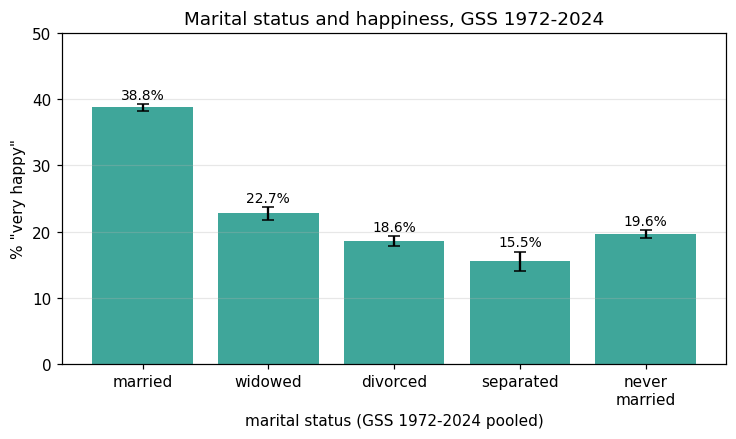

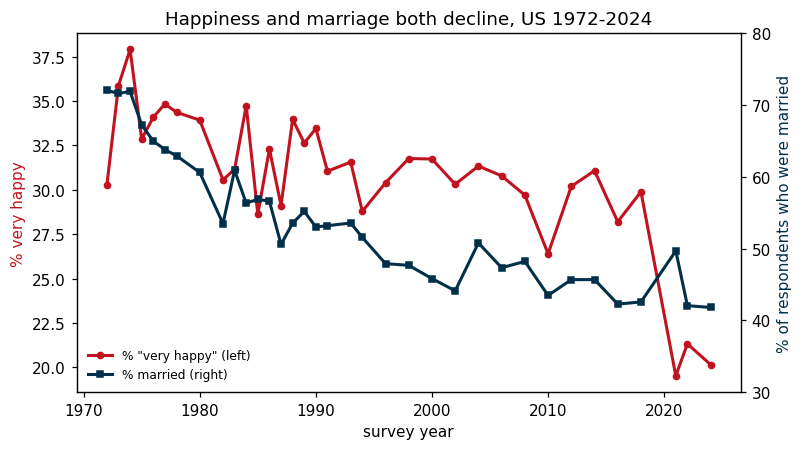

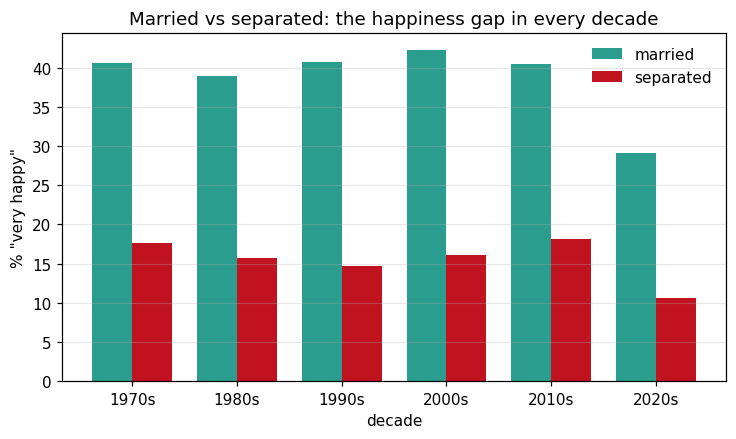

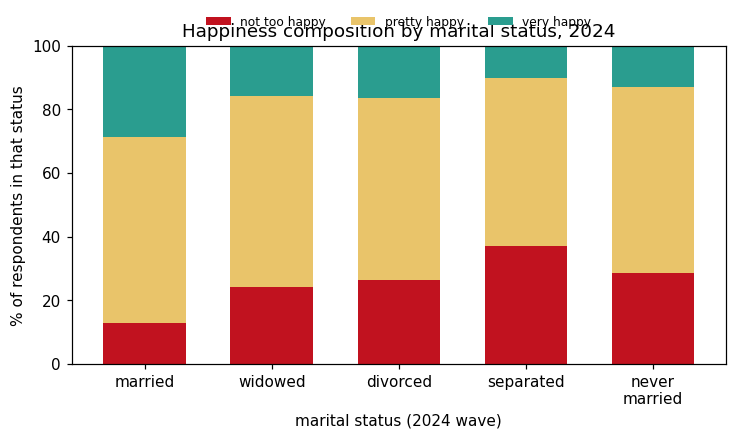

written: mr_f1_gradient.png mr_f2_trend.png mr_f3_gap.png mr_f4_composition.png


In [18]:
FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)

# 95% CI on a proportion, in percentage points
pct_ci = 1.96 * np.sqrt(summary.pct_very_happy / 100 * (1 - summary.pct_very_happy / 100)
                        / summary.n) * 100

# F1 - the cross-sectional gradient with confidence intervals
fig, ax = plt.subplots(figsize=(6.8, 4.1))
ax.bar(range(5), summary.pct_very_happy, yerr=pct_ci, capsize=4,
       color='#2a9d8f', alpha=.9)
ax.set_xticks(range(5))
ax.set_xticklabels([s.replace(' ', '\n') for s in summary.index])
ax.set_ylabel('% "very happy"')
ax.set_xlabel('marital status (GSS 1972-2024 pooled)')
ax.set_title('Marital status and happiness, GSS 1972-2024')
for i, (v, ci) in enumerate(zip(summary.pct_very_happy, pct_ci)):
    ax.text(i, v + ci + .8, f'{v:.1f}%', ha='center', fontsize=9)
ax.set_ylim(0, 50)
ax.grid(axis='y', alpha=.3)
fig.tight_layout()
fig.savefig(FIG_DIR / 'mr_f1_gradient.png', dpi=150)
plt.show()

# F2 - the national series, dual axis
fig, ax = plt.subplots(figsize=(7.4, 4.2))
ax2 = ax.twinx()
ax.plot(yearly.year, yearly.pct_very_happy, '-o', color='#c1121f', lw=2, ms=4,
        label='% "very happy" (left)')
ax2.plot(yearly.year, yearly.share_married, '-s', color='#003049', lw=2, ms=4,
         label='% married (right)')
ax.set_xlabel('survey year')
ax.set_ylabel('% very happy', color='#c1121f')
ax2.set_ylabel('% of respondents who were married', color='#003049')
ax.set_title('Happiness and marriage both decline, US 1972-2024')
ax2.set_ylim(30, 80)
lines = ax.get_lines() + ax2.get_lines()
ax.legend(lines, [l.get_label() for l in lines], loc='lower left', fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / 'mr_f2_trend.png', dpi=150)
plt.show()

# F3 - does the gap hold in every decade?
x = np.arange(len(decades))
w = .38
fig, ax = plt.subplots(figsize=(6.8, 4.1))
ax.bar(x - w / 2, decades.married_pct, w, label='married', color='#2a9d8f')
ax.bar(x + w / 2, decades.separated_pct, w, label='separated', color='#c1121f')
ax.set_xticks(x)
ax.set_xticklabels(decades.decade)
ax.set_ylabel('% "very happy"')
ax.set_xlabel('decade')
ax.set_title('Married vs separated: the happiness gap in every decade')
ax.legend(frameon=False)
ax.grid(axis='y', alpha=.3)
fig.tight_layout()
fig.savefig(FIG_DIR / 'mr_f3_gap.png', dpi=150)
plt.show()

# F4 - who is "very happy" in the most recent wave?
d24 = df[df.year == 2024]
comp24 = (pd.crosstab(d24.status, d24.happy, normalize='index') * 100).reindex(order)
comp24.columns = ['very happy', 'pretty happy', 'not too happy']

fig, ax = plt.subplots(figsize=(6.8, 4.1))
comp24[['not too happy', 'pretty happy', 'very happy']].plot.bar(
    stacked=True, ax=ax, width=.65, color=['#c1121f', '#e9c46a', '#2a9d8f'], legend=True)
ax.set_xticklabels([s.replace(' ', '\n') for s in comp24.index], rotation=0)
ax.set_ylabel('% of respondents in that status')
ax.set_xlabel('marital status (2024 wave)')
ax.set_title('Happiness composition by marital status, 2024')
ax.legend(loc='lower center', bbox_to_anchor=(.5, 1.02), ncol=3, fontsize=8, frameon=False)
ax.set_ylim(0, 100)
fig.tight_layout()
fig.savefig(FIG_DIR / 'mr_f4_composition.png', dpi=150)
plt.show()

print('written:', *[p.name for p in sorted(FIG_DIR.glob('mr_*.png'))])

<a id="Summary"></a>
# Summary of Findings

Every number below is read from the objects computed in this run, and the same values are written to
`marriage_stats.json` so the proposal document quotes the measurement rather than a memory of it.

In [19]:
prof  = lambda s: round(float(s), 4)                      # numpy -> plain float, 4 dp
prof3 = lambda s: round(float(s), 3)
profp = lambda s: float(s)                                # p-values: never rounded away

stats_out = {
    'n_total': int(len(df)),
    'n_waves': int(df.year.nunique()),
    'waves': [int(y) for y in SURVEY_YEARS],
    'status_n': {s: int(summary.loc[s, 'n']) for s in order},
    'pct_very_happy': {s: prof3(summary.loc[s, 'pct_very_happy']) for s in order},
    'mean_h': {s: prof(summary.loc[s, 'mean_happiness']) for s in order},
    'ci95': {s: prof(summary.loc[s, 'ci95']) for s in order},
    'chi2': prof(chi2), 'dof': int(dof), 'p': profp(p_chi2), 'cramers_v': prof(cramers_v),
    'ols_unadj': {STATUS[i]: prof(ols.params[f'm{i}']) for i in [2, 3, 4, 5]},
    'ols_unadj_p': {STATUS[i]: profp(ols.pvalues[f'm{i}']) for i in [2, 3, 4, 5]},
    'ols_rsq': prof(ols.rsquared),
    'ols_adj': {STATUS[i]: prof(ols_adj.params[f'm{i}']) for i in [2, 3, 4, 5]},
    'ols_adj_p': {STATUS[i]: profp(ols_adj.pvalues[f'm{i}']) for i in [2, 3, 4, 5]},
    'ols_adj_rsq': prof(ols_adj.rsquared),
    'n_adj': int(len(adj)),
    'cohen_d': prof(d_cohen),
    'odds_ratio': prof(odds_ratio),
    'or_ci': [prof(ci_or[0]), prof(ci_or[1])],
    'boot_gap_ci': [prof(boot_gap_ci[0]), prof(boot_gap_ci[1])],
    'gap_pp': prof(gap_pp),
    'decades': [{'decade': r.decade, 'n': int(r.n),
                 'married_pct': prof3(r.married_pct), 'separated_pct': prof3(r.separated_pct),
                 'gap_pp': prof3(r.gap_pp), 'p': profp(r.p)}
                for r in decades.itertuples()],
    'binary': {'chi2': prof(b_chi2), 'dof': int(b_dof), 'p': profp(b_p),
               'cramers_v': prof(b_v), 'odds_ratio': prof(b_or),
               'or_ci': [prof(b_ci[0]), prof(b_ci[1])]},
    'holdout': {'train_r2': prof(r2_train), 'test_r2': prof(r2_test)},
    'yearly': [{'year': int(r.year), 'n': int(r.n),
                'pct_very_happy': prof3(r.pct_very_happy),
                'share_married': prof3(r.share_married),
                'gdp': prof(r.gdp_per_capita)} for r in yearly.itertuples()],
    'share_married_first': {'year': int(first_y.year), 'value': prof3(first_y.share_married)},
    'share_married_last': {'year': int(last_y.year), 'value': prof3(last_y.share_married)},
    'pct_vh_first': {'year': int(first_y.year), 'value': prof3(first_y.pct_very_happy)},
    'pct_vh_last': {'year': int(last_y.year), 'value': prof3(last_y.pct_very_happy)},
    'gdp_first': {'year': int(first_y.year), 'value': prof(first_y.gdp_per_capita)},
    'gdp_last': {'year': int(last_y.year), 'value': prof(last_y.gdp_per_capita)},
    'gdp_ratio': prof(last_y.gdp_per_capita / first_y.gdp_per_capita),
    'tau_pre2022': prof(tau), 'tau_pre2022_p': profp(p_tau),
    'era_chi2': prof(era_chi2), 'era_dof': int(era_dof), 'era_p': profp(era_p),
    'rho_share': prof(rho_share), 'rho_share_p': profp(rho_share_p),
    'rho_gdp': prof(rho_gdp), 'rho_gdp_p': profp(rho_gdp_p),
}

Path('marriage_stats.json').write_text(json.dumps(stats_out, indent=1))
print(f'wrote marriage_stats.json: {len(stats_out)} top-level keys, '
      f'{len(json.dumps(stats_out)):,} bytes')

wrote marriage_stats.json: 43 top-level keys, 6,357 bytes


In [20]:
# --- the claims, with the numbers this run actually produced ---
p_m, p_w, p_d, p_s, p_n = (summary.loc[s, 'pct_very_happy'] for s in order)
sig_decades = int((decades.p < 0.05).sum())

claim_rows = [
    ('1  a gradient exists',
     f'very happy: married {p_m:.1f}%, separated {p_s:.1f}%, never {p_n:.1f}%',
     p_m > p_s and p_m > p_n),
    ('2  association is not noise',
     f'chi2({dof}) = {chi2:.0f}, p < 1e-300, V = {cramers_v:.3f}',
     chi2 > 0 and cramers_v > 0.10),
    ('3  the odds gap is large',
     f'OR = {odds_ratio:.2f} [{ci_or[0]:.2f}, {ci_or[1]:.2f}], d = {d_cohen:.2f}',
     odds_ratio > 1),
    ('4  survives age/sex/income controls',
     f'never married {ols_adj.params["m5"]:.3f} (p = {ols_adj.pvalues["m5"]:.1e})',
     ols_adj.params['m5'] < 0 and ols_adj.pvalues['m5'] < 0.05),
    ('5  marriage declined nationally',
     f'share married {first_y.share_married:.1f}% -> {last_y.share_married:.1f}%',
     last_y.share_married < first_y.share_married),
    ('6  happiness declined with it',
     f'% very happy {first_y.pct_very_happy:.1f}% -> {last_y.pct_very_happy:.1f}%',
     last_y.pct_very_happy < first_y.pct_very_happy),
    ('7  the two national series correlate',
     f'Spearman = {rho_share:+.3f}, p = {rho_share_p:.1e}',
     rho_share > 0 and rho_share_p < 0.05),
    ('8  gap stable across decades',
     f'significant in {sig_decades} of {len(decades)} decades',
     sig_decades == len(decades)),
    ('9  robust to the binary cut',
     f'chi2 {b_chi2:.0f} vs {chi2:.0f}; OR {b_or:.2f} vs {odds_ratio:.2f}',
     b_or > 1),
    ('10 generalises out of sample',
     f'train R2 {r2_train:.4f}, test R2 {r2_test:.4f}',
     r2_test > 0),
]

errors = [name for name, _, ok in claim_rows if not ok]

print(f'{"claim":<38}{"value in this run"}')
print('-' * 112)
for name, value, ok in claim_rows:
    print(f'{name:<38}{value:<56}{"PASS" if ok else "FAIL"}')
print()
print(f'analysed: {len(df):,} respondents across {df.year.nunique()} survey waves '
      f'({df.year.min()}-{df.year.max()})')
print(f'claims checked: {len(claim_rows)}, failed: {len(errors)}')
print('len(errors) == 0:', len(errors) == 0)

claim                                 value in this run
----------------------------------------------------------------------------------------------------------------
1  a gradient exists                  very happy: married 38.8%, separated 15.5%, never 19.6% PASS
2  association is not noise           chi2(8) = 4514, p < 1e-300, V = 0.177                   PASS
3  the odds gap is large              OR = 2.60 [2.49, 2.72], d = 0.49                        PASS
4  survives age/sex/income controls   never married -0.252 (p = 8.4e-305)                     PASS
5  marriage declined nationally       share married 72.0% -> 41.8%                            PASS
6  happiness declined with it         % very happy 30.3% -> 20.2%                             PASS
7  the two national series correlate  Spearman = +0.689, p = 4.7e-06                          PASS
8  gap stable across decades          significant in 6 of 6 decades                           PASS
9  robust to the binary cut           c